# **Tugas Akhir**   
### Analisis Perbandingan Model Deep Learning untuk Klasifikasi Emosi pada Teks Opini Publik Berbahasa Indonesia

2372023 - Eben Praus Yosia



---



# Part 8b: RoBERTa - Skema 2 "Tokenizer" (fine-tuning penuh)
Tokenizer BPE RoBERTa Indonesia + bobot pre-trained `flax-community/indonesian-roberta-base` -> kepala klasifikasi baru (6 kelas) -> fine-tuning penuh

RoBERTa memakai tokenizer aslinya sendiri (bukan tokenizer IndoBERT). Tidak ada yang dibekukan (frozen)

Aturan: satu run, tanpa grid search; evaluasi hanya di validation; test set tidak disentuh.

- Input : `data/train.csv`, `data/val.csv`, `data/label_map.json`
- Output: `outputs/roberta_tokenizer_val_results.json`, `outputs/models/roberta_tokenizer.pt`, grafik di `outputs/figures/`

### Step 1 - Konfigurasi, seed, dan load data

In [1]:
import os, json, re, random, time
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from transformers import AutoTokenizer, AutoModelForSequenceClassification, get_linear_schedule_with_warmup
from torch.utils.data import DataLoader
from sklearn.metrics import (accuracy_score, f1_score, precision_score, recall_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)

DATA_DIR = "data"
FIG_DIR = "outputs/figures"
MODEL_DIR = "outputs/models"
RESULT_PATH = "outputs/roberta_tokenizer_val_results.json"

TEXT_COL, LABEL_COL = "text", "label"
SEED = 42

# Tokenizer dan bobot pre-trained milik RoBERTa sendiri (RoBERTa, byte-level BPE)
MODEL_NAME = "flax-community/indonesian-roberta-base"
MAX_LEN = 128 # dalam token subword (termasuk token khusus)

# Hyperparameter tetap, standar fine-tuning Transformer (tanpa tuning)
BATCH_SIZE = 32
EPOCHS = 15
LR = 2e-5
WEIGHT_DECAY = 0.01
WARMUP_RATIO = 0.1
CLIP_NORM = 1.0


for d in (FIG_DIR, MODEL_DIR): os.makedirs(d, exist_ok=True)
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

train_df = pd.read_csv(f"{DATA_DIR}/train.csv")
val_df   = pd.read_csv(f"{DATA_DIR}/val.csv")

with open(f"{DATA_DIR}/label_map.json") as f:
    label_map = json.load(f)
labels = list(label_map.keys()) # urutan: anger, fear, joy, love, neutral, sad
NUM_CLASSES = len(labels)
assert all(label_map[l] == i for i, l in enumerate(labels))
y_train_list = [label_map[l] for l in train_df[LABEL_COL]]
y_val_list   = [label_map[l] for l in val_df[LABEL_COL]]
print("Train:", train_df.shape, "| Val:", val_df.shape, "| Kelas:", labels)

Train: (4921, 2) | Val: (1055, 2) | Kelas: ['anger', 'fear', 'joy', 'love', 'neutral', 'sad']


### Step 2 - Tokenizer subword asli RoBERTa
Skema 2 "Tokenizer":  
Pada skema ini, RoBERTa menggunakan tokenizer subword asli miliknya sendiri (checkpoint: flax-community/indonesian-roberta-base).

In [2]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
if tokenizer.pad_token_id is None: # jika checkpoint tidak mendefinisikan pad token
    tokenizer.pad_token = "<pad>"
print(f"Checkpoint: {MODEL_NAME} | vocab subword: {len(tokenizer)} | pad id: {tokenizer.pad_token_id}")

contoh = train_df[TEXT_COL].iloc[0]
print("Contoh teks:", contoh[:80])
print("Subword:", tokenizer.tokenize(contoh)[:12])

# Token khusus ([CLS]/[SEP] atau <s>/</s>) ditambahkan otomatis oleh tokenizer. Padding dilakukan per batch (dinamis).
train_ids = tokenizer(train_df[TEXT_COL].tolist(), truncation=True, max_length=MAX_LEN)["input_ids"]
val_ids = tokenizer(val_df[TEXT_COL].tolist(), truncation=True, max_length=MAX_LEN)["input_ids"]

full_len = np.array([len(x) for x in tokenizer(train_df[TEXT_COL].tolist(), truncation=False)["input_ids"]])
trunc_pct = (full_len > MAX_LEN).mean() * 100
VOCAB_SIZE = len(tokenizer)
print(f"Panjang subword train (dengan token khusus): rata-rata {full_len.mean():.1f} | persentil 95 = {np.percentile(full_len, 95):.0f} | maks = {full_len.max()}")
print(f"Teks train yang terpotong oleh MAX_LEN={MAX_LEN}: {trunc_pct:.2f}%")
PAD_FOR_COLLATE = tokenizer.pad_token_id

config.json:   0%|          | 0.00/671 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/292 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/808k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/467k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.38M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

Checkpoint: flax-community/indonesian-roberta-base | vocab subword: 50265 | pad id: 1
Contoh teks: 365. kalau mau gestun limit kamu di spaylater, gopay coin, gopaylater, akulaku, 
Subword: ['365', '.', 'Ġkalau', 'Ġmau', 'Ġg', 'est', 'un', 'Ġlimit', 'Ġkamu', 'Ġdi', 'Ġsp', 'ay']
Panjang subword train (dengan token khusus): rata-rata 24.9 | persentil 95 = 62 | maks = 93
Teks train yang terpotong oleh MAX_LEN=128: 0.00%


In [3]:
def make_collate(pad_id):
    def collate(batch): # batch: list of (ids, label); pad ke panjang terpanjang di batch
        L = max(len(ids) for ids, _ in batch)
        input_ids = torch.full((len(batch), L), pad_id, dtype=torch.long)
        attn = torch.zeros((len(batch), L), dtype=torch.long)
        for i, (ids, _) in enumerate(batch):
            input_ids[i, :len(ids)] = torch.tensor(ids)
            attn[i, :len(ids)] = 1
        return {"input_ids": input_ids, "attention_mask": attn,
                "labels": torch.tensor([y for _, y in batch], dtype=torch.long)}
    return collate

collate_fn = make_collate(PAD_FOR_COLLATE)
train_loader = DataLoader(list(zip(train_ids, y_train_list)), batch_size=BATCH_SIZE, shuffle=True,
                          collate_fn=collate_fn, generator=torch.Generator().manual_seed(SEED))
val_loader = DataLoader(list(zip(val_ids, y_val_list)), batch_size=64, shuffle=False, collate_fn=collate_fn)
b0 = next(iter(val_loader))
print("Contoh batch -> input_ids:", tuple(b0["input_ids"].shape), "| attention_mask:", tuple(b0["attention_mask"].shape))

Contoh batch -> input_ids: (64, 65) | attention_mask: (64, 65)


### Step 3 - Muat RoBERTa pre-trained (fine-tuning penuh)

In [4]:
# num_labels=6 -> kepala klasifikasi baru (acak)
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME, num_labels=NUM_CLASSES,
    id2label={i: l for i, l in enumerate(labels)}, label2id=label_map).to(device)
n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

# Fine-tuning penuh: tidak ada yang dibekukan
assert all(p.requires_grad for p in model.parameters())
print(f"Arsitektur: {model.config.model_type} | layer: {model.config.num_hidden_layers} | hidden: {model.config.hidden_size}")
print(f"Total parameter dilatih: {n_params/1e6:.1f} juta (semua requires_grad = True, fine-tuning penuh)")

model.safetensors: reconstructing file:   0%|          |  0.00B /  499MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: flax-community/indonesian-roberta-base
Key                        | Status     | 
---------------------------+------------+-
lm_head.layer_norm.weight  | UNEXPECTED | 
lm_head.dense.weight       | UNEXPECTED | 
lm_head.bias               | UNEXPECTED | 
lm_head.dense.bias         | UNEXPECTED | 
lm_head.layer_norm.bias    | UNEXPECTED | 
classifier.out_proj.weight | MISSING    | 
classifier.dense.weight    | MISSING    | 
classifier.dense.bias      | MISSING    | 
classifier.out_proj.bias   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Arsitektur: roberta | layer: 12 | hidden: 768
Total parameter dilatih: 124.7 juta (semua requires_grad = True, fine-tuning penuh)


### Step 4 - Training (satu run, 15 epoch, model epoch terakhir yang dievaluasi)
Loss `CrossEntropyLoss` (tanpa class weight)  
Optimizer AdamW  
Warmup 10% lalu penurunan linear, gradient clipping 1.0, mixed precision di GPU  
Tidak memilih epoch terbaik di validation  
Akan ditunjukkan lewat grafik jika seandainya terjadi overfitting

In [5]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
total_steps = EPOCHS * len(train_loader)
scheduler = get_linear_schedule_with_warmup(optimizer, int(WARMUP_RATIO * total_steps), total_steps)
use_amp = device.type == "cuda" # mixed precision (fp16) di GPU: lebih cepat & hemat memori
scaler = torch.amp.GradScaler("cuda", enabled=use_amp)

def run_epoch(loader, train):
    model.train(train)
    tot_loss, correct, n = 0.0, 0, 0
    with torch.set_grad_enabled(train):
        for batch in loader:
            ids = batch["input_ids"].to(device); am = batch["attention_mask"].to(device); yb = batch["labels"].to(device)
            with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=use_amp):
                logits = model(input_ids=ids, attention_mask=am).logits
            loss = criterion(logits.float(), yb)
            if train:
                optimizer.zero_grad()
                scaler.scale(loss).backward()
                scaler.unscale_(optimizer)
                torch.nn.utils.clip_grad_norm_(model.parameters(), CLIP_NORM)
                scaler.step(optimizer); scaler.update(); scheduler.step()
            tot_loss += loss.item() * len(yb)
            correct += (logits.argmax(1) == yb).sum().item()
            n += len(yb)
    return tot_loss / n, correct / n

history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
t0 = time.time()
for ep in range(1, EPOCHS + 1):
    tr_loss, tr_acc = run_epoch(train_loader, train=True)
    va_loss, va_acc = run_epoch(val_loader,   train=False)
    for k, v in zip(history, (tr_loss, va_loss, tr_acc, va_acc)): history[k].append(v)
    print(f"Epoch {ep:2d}/{EPOCHS} | train loss {tr_loss:.4f} acc {tr_acc:.4f} | val loss {va_loss:.4f} acc {va_acc:.4f} | {time.time()-t0:.0f} dtk")
print(f"Selesai dalam {time.time()-t0:.0f} detik")

torch.save(model.state_dict(), f"{MODEL_DIR}/roberta_tokenizer.pt") # ukuran file bisa ratusan MB

Epoch  1/15 | train loss 1.5850 acc 0.3583 | val loss 1.0611 acc 0.6161 | 23 dtk
Epoch  2/15 | train loss 0.8196 acc 0.7242 | val loss 0.6702 acc 0.7640 | 46 dtk
Epoch  3/15 | train loss 0.5384 acc 0.8137 | val loss 0.6569 acc 0.7839 | 68 dtk
Epoch  4/15 | train loss 0.3538 acc 0.8811 | val loss 0.7265 acc 0.7791 | 90 dtk
Epoch  5/15 | train loss 0.2256 acc 0.9256 | val loss 0.8359 acc 0.7706 | 114 dtk
Epoch  6/15 | train loss 0.1402 acc 0.9596 | val loss 0.8499 acc 0.7886 | 138 dtk
Epoch  7/15 | train loss 0.0860 acc 0.9748 | val loss 1.0340 acc 0.7668 | 161 dtk
Epoch  8/15 | train loss 0.0532 acc 0.9846 | val loss 1.1048 acc 0.7791 | 185 dtk
Epoch  9/15 | train loss 0.0339 acc 0.9907 | val loss 1.1978 acc 0.7763 | 209 dtk
Epoch 10/15 | train loss 0.0198 acc 0.9945 | val loss 1.2141 acc 0.7858 | 233 dtk
Epoch 11/15 | train loss 0.0137 acc 0.9972 | val loss 1.2572 acc 0.7905 | 256 dtk
Epoch 12/15 | train loss 0.0138 acc 0.9963 | val loss 1.3430 acc 0.7839 | 280 dtk
Epoch 13/15 | train 

### Step 5 - Kurva training vs validation (loss & accuracy)

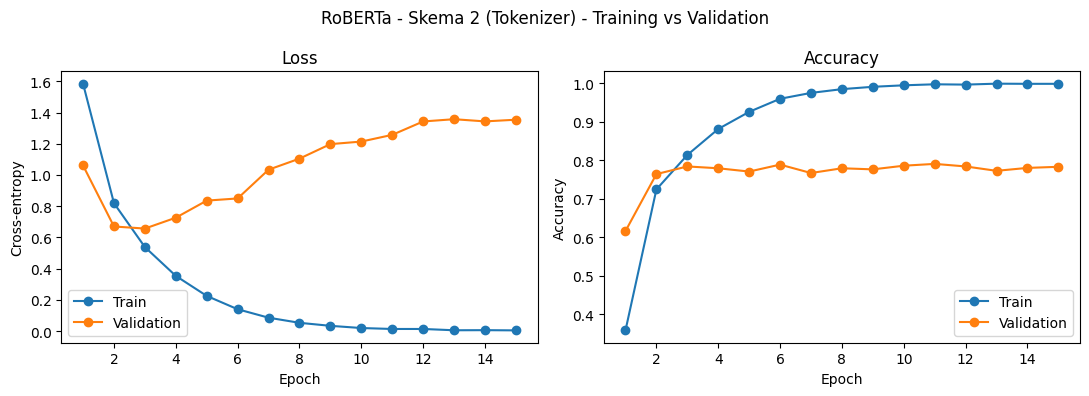

Val loss terendah di epoch 3 (0.6569); epoch terakhir: 1.3542


In [6]:
ep_axis = range(1, EPOCHS + 1)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(ep_axis, history["train_loss"], "o-", label="Train")
axes[0].plot(ep_axis, history["val_loss"], "o-", label="Validation")
axes[0].set_title("Loss"); axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Cross-entropy"); axes[0].legend()
axes[1].plot(ep_axis, history["train_acc"], "o-", label="Train")
axes[1].plot(ep_axis, history["val_acc"], "o-", label="Validation")
axes[1].set_title("Accuracy"); axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Accuracy"); axes[1].legend()
fig.suptitle("RoBERTa - Skema 2 (Tokenizer) - Training vs Validation")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/08b_roberta_tokenizer_curves.png", dpi=150)
plt.show()

best_ep = int(np.argmin(history["val_loss"])) + 1
print(f"Val loss terendah di epoch {best_ep} ({min(history['val_loss']):.4f}); epoch terakhir: {history['val_loss'][-1]:.4f}")

### Step 6 - Evaluasi di validation set (model epoch terakhir)

In [7]:
model.eval()
preds = []
with torch.no_grad():
    for batch in val_loader:
        with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=use_amp):
            logits = model(input_ids=batch["input_ids"].to(device), attention_mask=batch["attention_mask"].to(device)).logits
        preds.append(logits.argmax(1).cpu())
pred_idx = torch.cat(preds).numpy()

y_val_str = val_df[LABEL_COL].values
y_pred_str = np.array([labels[i] for i in pred_idx])

acc = accuracy_score(y_val_str, y_pred_str)
macro_p = precision_score(y_val_str, y_pred_str, average="macro", zero_division=0)
macro_r = recall_score(y_val_str, y_pred_str, average="macro", zero_division=0)
macro_f1 = f1_score(y_val_str, y_pred_str, average="macro")

kelas_terbanyak = train_df[LABEL_COL].value_counts().idxmax()
acc_mayoritas = (val_df[LABEL_COL] == kelas_terbanyak).mean()
print(f"Acuan 'tebak selalu {kelas_terbanyak}': accuracy = {acc_mayoritas:.4f}")
print(f"RoBERTa - Skema 2 (Tokenizer) (val): accuracy = {acc:.4f} | macro-F1 = {macro_f1:.4f}")
print("Jumlah kelas yang pernah diprediksi:", len(set(y_pred_str)), "dari", NUM_CLASSES)

# Satu tabel: per kelas + accuracy + macro avg + weighted avg
rapor = classification_report(y_val_str, y_pred_str, labels=labels, output_dict=True, zero_division=0)
rapor_df = pd.DataFrame(rapor).T.drop(index="accuracy")
rapor_df.loc["accuracy"] = [np.nan, np.nan, acc, len(y_val_str)]
rapor_df = rapor_df.loc[labels + ["accuracy", "macro avg", "weighted avg"]]
rapor_df["support"] = rapor_df["support"].astype(int)
rapor_df.round(4).fillna("")

Acuan 'tebak selalu neutral': accuracy = 0.2825
RoBERTa - Skema 2 (Tokenizer) (val): accuracy = 0.7829 | macro-F1 = 0.7898
Jumlah kelas yang pernah diprediksi: 6 dari 6


,precision,recall,f1-score,support
anger,0.8025,0.75,0.7754,168
fear,0.8182,0.8603,0.8387,136
joy,0.7463,0.8095,0.7766,189
love,0.7111,0.8496,0.7742,113
neutral,0.8,0.6846,0.7378,298
sad,0.8125,0.8609,0.8360,151
accuracy,,,0.7829,1055
macro avg,0.7818,0.8025,0.7898,1055
weighted avg,0.7854,0.7829,0.7817,1055


### Step 7 - Confusion matrix (validation)

,pred_anger,pred_fear,pred_joy,pred_love,pred_neutral,pred_sad
asli_anger,126,8,5,6,15,8
asli_fear,6,117,3,1,5,4
asli_joy,3,3,153,11,13,6
asli_love,5,1,4,96,7,0
asli_neutral,17,13,33,19,204,12
asli_sad,0,1,7,2,11,130


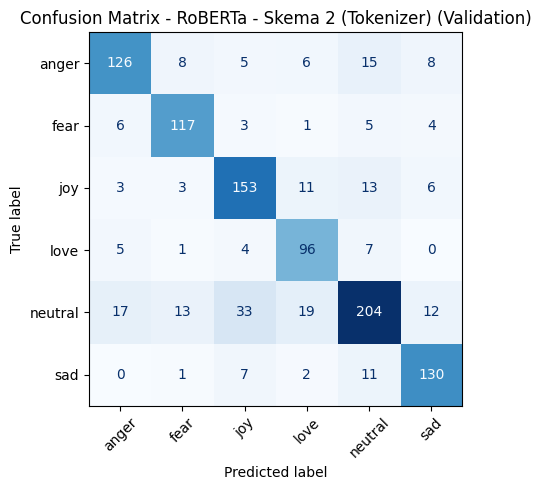

In [8]:
cm = confusion_matrix(y_val_str, y_pred_str, labels=labels)
display(pd.DataFrame(cm, index=[f"asli_{l}" for l in labels], columns=[f"pred_{l}" for l in labels]))

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(cm, display_labels=labels).plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title("Confusion Matrix - RoBERTa - Skema 2 (Tokenizer) (Validation)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/08b_roberta_tokenizer_confusion_matrix_val.png", dpi=150)
plt.show()

### Step 8 - Simpan hasil

In [9]:
# Format JSON seragam (kunci inti sama: model, feature_extraction, split, accuracy, dll)
with open(RESULT_PATH, "w") as f:
    json.dump({"model": "RoBERTa", "feature_extraction": "tokenizer", "split": "validation",
               "accuracy": round(float(acc), 4), "macro_precision": round(float(macro_p), 4),
               "macro_recall": round(float(macro_r), 4), "macro_f1": round(float(macro_f1), 4),
               "extractor": "tokenizer + bobot pretrained flax-community/indonesian-roberta-base, fine-tuning penuh",
               "vocab_size": int(VOCAB_SIZE), "max_len": int(MAX_LEN), "epochs": EPOCHS, "lr": LR,
               "batch_size": BATCH_SIZE, "n_trainable_params": int(n_params), "evaluated_epoch": "last"}, f, indent=2)
print("Tersimpan:", RESULT_PATH)

Tersimpan: outputs/roberta_tokenizer_val_results.json


### Notes Part 8b:
- Vocabulary | MAX_LEN | parameter dilatih: 50265 | 128 | 124.7 juta
- Teks train terpotong oleh MAX_LEN: 0.00%
- Train acc | Val acc (epoch terakhir): 0.9984 | 0.7829
- Val loss terendah di epoch: epoch ke-3 (epoch terakhir: 15)
- Accuracy | Macro-F1 (validation): 0.7829 | 0.7898 (acuan tebak-mayoritas: 0.2825)
- Macro-Precision | Macro-Recall: 0.7818 | 0.8025
- F1 tertinggi | terendah per kelas: fear (0.8387) | neutral (0.7378)
- Pasangan kelas yang paling sering tertukar: joy dan neutral (46 kesalahan di dua arah)
- Test set belum disentuh.